In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/Users/sreeharivenkataraman/Personal Files/DS_Projects/project_2/online_food_delivery_analysis/dataset/online_food_delivery_univariate.csv")

In [4]:
df_clean = df.copy()
age_order = (
    df_clean[
        df_clean["Age_Group"] != "Unknown"
    ]
    .groupby(
        "Age_Group",
        observed=True
    )
    .agg(
        Order_Count=("Order_ID", "count"),
        Average_Order_Value=("Order_Value", "mean"),
        Median_Order_Value=("Order_Value", "median")
    )
    .reset_index()
)

age_order

,Age_Group,Order_Count,Average_Order_Value,Median_Order_Value
0,Adult,11653,1806.888441,1197.0
1,Middle Age,11622,1766.813199,1197.0
2,Senior Adult,17386,1786.419418,1197.0
3,Young Adult,9246,1782.305970,1197.0


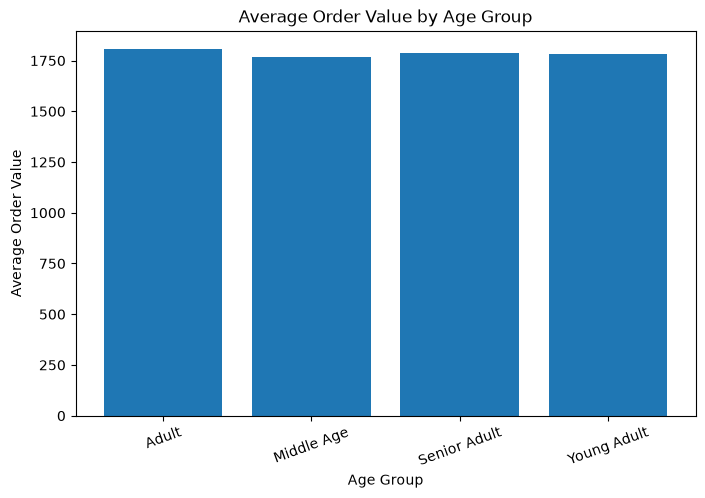

In [5]:
plt.figure(figsize=(8, 5))

plt.bar(
    age_order["Age_Group"],
    age_order["Average_Order_Value"]
)

plt.xlabel("Age Group")
plt.ylabel("Average Order Value")
plt.title("Average Order Value by Age Group")

plt.xticks(rotation=20)

plt.show()

In [6]:
day_orders = (
    df_clean
    .groupby("Order_Day")
    .agg(
        Total_Orders=("Order_ID", "count"),
        Average_Order_Value=("Order_Value", "mean"),
        Revenue=("Revenue", "sum")
    )
    .reset_index()
)

day_orders

,Order_Day,Total_Orders,Average_Order_Value,Revenue
0,Weekday,71370,1789.416968,103366189.0
1,Weekend,28630,1780.775061,41234379.0


In [7]:
day_orders["Order_Percentage"] = (
    day_orders["Total_Orders"]
    / day_orders["Total_Orders"].sum()
    * 100
)

day_orders

,Order_Day,Total_Orders,Average_Order_Value,Revenue,Order_Percentage
0,Weekday,71370,1789.416968,103366189.0,71.37
1,Weekend,28630,1780.775061,41234379.0,28.63


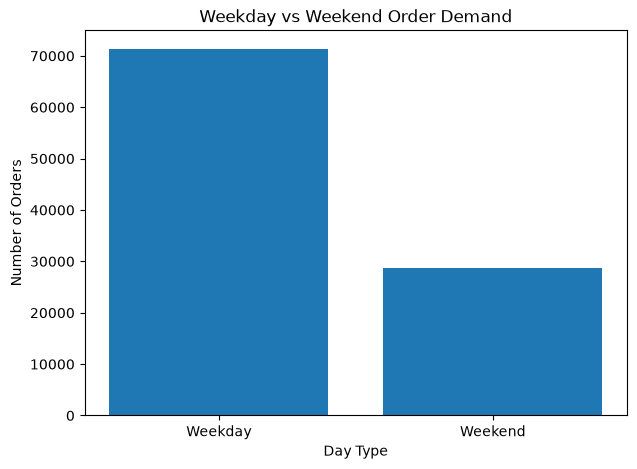

In [8]:
plt.figure(figsize=(7, 5))

plt.bar(
    day_orders["Order_Day"],
    day_orders["Total_Orders"]
)

plt.xlabel("Day Type")
plt.ylabel("Number of Orders")
plt.title("Weekday vs Weekend Order Demand")

plt.show()

In [9]:
daily_orders = (
    df_clean
    .dropna(subset=["Order_Date"])
    .groupby(
        ["Order_Date", "Order_Day"]
    )
    .size()
    .reset_index(name="Orders")
)

In [10]:
daily_orders.groupby(
    "Order_Day"
)["Orders"].mean()

Order_Day
Weekday    270.567050
Weekend    272.769231
Name: Orders, dtype: float64

In [11]:
city_revenue = (
    df_clean[
        df_clean["City"] != "Unknown"
    ]
    .groupby("City")
    .agg(
        Total_Orders=("Order_ID", "count"),
        Total_Revenue=("Revenue", "sum"),
        Average_Order_Value=("Order_Value", "mean")
    )
    .reset_index()
    .sort_values(
        "Total_Revenue",
        ascending=False
    )
)

city_revenue

,City,Total_Orders,Total_Revenue,Average_Order_Value
0,Bangalore,16732,24383817.0,1797.850167
3,Hyderabad,16884,24202390.0,1776.917733
2,Delhi,16695,24033962.0,1778.178257
1,Chennai,16470,23890200.0,1794.836733
4,Mumbai,16493,23866077.0,1783.886134


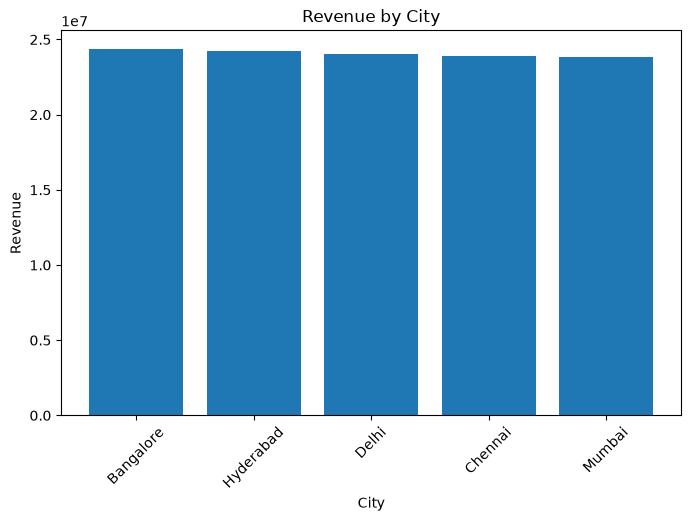

In [12]:
plt.figure(figsize=(8, 5))

plt.bar(
    city_revenue["City"],
    city_revenue["Total_Revenue"]
)

plt.xlabel("City")
plt.ylabel("Revenue")
plt.title("Revenue by City")

plt.xticks(rotation=45)

plt.show()

In [13]:
cuisine_revenue = (
    df_clean[
        df_clean["Cuisine_Type"] != "Unknown"
    ]
    .groupby("Cuisine_Type")
    .agg(
        Total_Orders=("Order_ID", "count"),
        Total_Revenue=("Revenue", "sum"),
        Average_Order_Value=("Order_Value", "mean")
    )
    .reset_index()
    .sort_values(
        "Total_Revenue",
        ascending=False
    )
)

cuisine_revenue

,Cuisine_Type,Total_Orders,Total_Revenue,Average_Order_Value
1,Chinese,16651,24188732.0,1787.149901
4,Mexican,16602,24167045.0,1792.863330
2,Indian,16685,24070979.0,1795.805933
0,Arabian,16658,23864552.0,1769.786409
3,Italian,16519,23695390.0,1778.286942


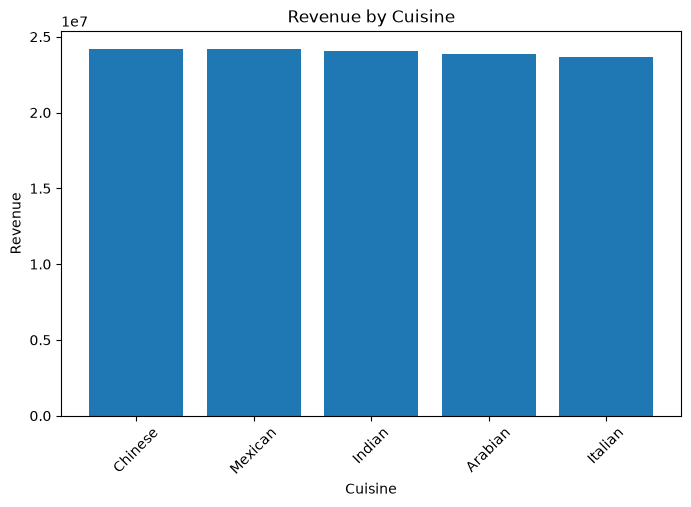

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    cuisine_revenue["Cuisine_Type"],
    cuisine_revenue["Total_Revenue"]
)

plt.xlabel("Cuisine")
plt.ylabel("Revenue")
plt.title("Revenue by Cuisine")

plt.xticks(rotation=45)

plt.show()

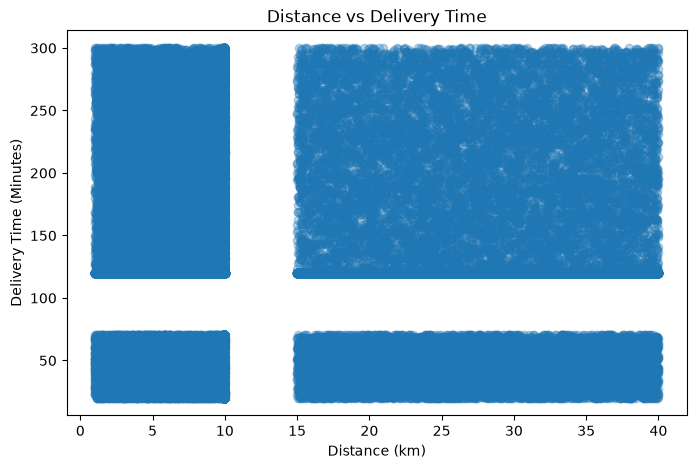

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Distance_km"],
    df_clean["Delivery_Time_Min"],
    alpha=0.3
)

plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (Minutes)")
plt.title("Distance vs Delivery Time")

plt.show()

In [16]:
df_clean[
    ["Distance_km", "Delivery_Time_Min"]
].corr()

,Distance_km,Delivery_Time_Min
Distance_km,1.000000,0.002227
Delivery_Time_Min,0.002227,1.000000


In [17]:
df_clean["Distance_km"].corr(
    df_clean["Delivery_Time_Min"]
)

np.float64(0.002226501534623397)

In [18]:
delivered_df = df_clean[
    df_clean["Order_Status"] == "Delivered"
]

In [19]:
rating_delivery = (
    delivered_df
    .groupby("Delivery_Rating")
    .agg(
        Average_Delivery_Time=(
            "Delivery_Time_Min",
            "mean"
        ),
        Order_Count=(
            "Order_ID",
            "count"
        )
    )
    .reset_index()
)

rating_delivery

,Delivery_Rating,Average_Delivery_Time,Order_Count
0,1.0,125.047509,14292
1,2.0,124.641163,14377
2,3.0,124.539928,27913
3,4.0,126.004870,14375
4,5.0,125.065896,14007


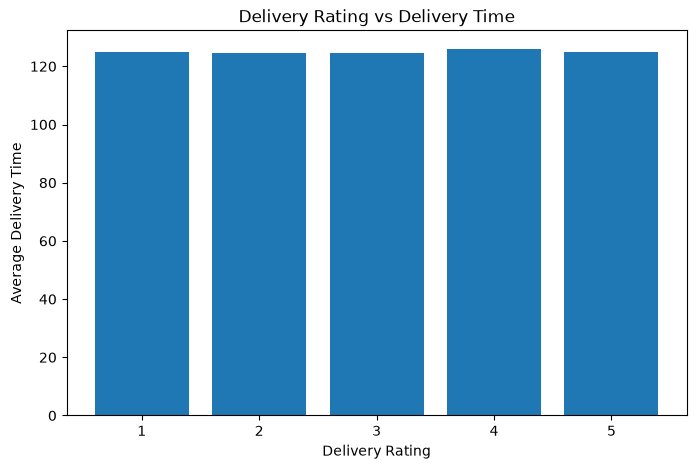

In [20]:
plt.figure(figsize=(8, 5))

plt.bar(
    rating_delivery["Delivery_Rating"],
    rating_delivery["Average_Delivery_Time"]
)

plt.xlabel("Delivery Rating")
plt.ylabel("Average Delivery Time")
plt.title("Delivery Rating vs Delivery Time")

plt.show()

In [21]:
delivered_df[
    "Delivery_Rating"
].corr(
    delivered_df["Delivery_Time_Min"]
)

np.float64(0.002461975296568477)

In [22]:
discount_profit = (
    df_clean
    .groupby("Discount_Applied")
    .agg(
        Order_Count=("Order_ID", "count"),
        Average_Profit=("Estimated_Profit", "mean"),
        Average_Revenue=("Revenue", "mean")
    )
    .reset_index()
)

discount_profit.head(10)

,Discount_Applied,Order_Count,Average_Profit,Average_Revenue
0,0.0,16650,377.250896,1519.791712
1,20.0,16569,372.671112,1497.750800
2,50.0,33405,365.987399,1475.522886
3,100.0,16776,358.504506,1437.370410
4,150.0,5,0.000000,0.000000
5,151.0,7,0.000000,0.000000
6,152.0,2,0.000000,0.000000
7,153.0,7,0.000000,0.000000
8,154.0,3,0.000000,0.000000
9,155.0,7,0.000000,0.000000


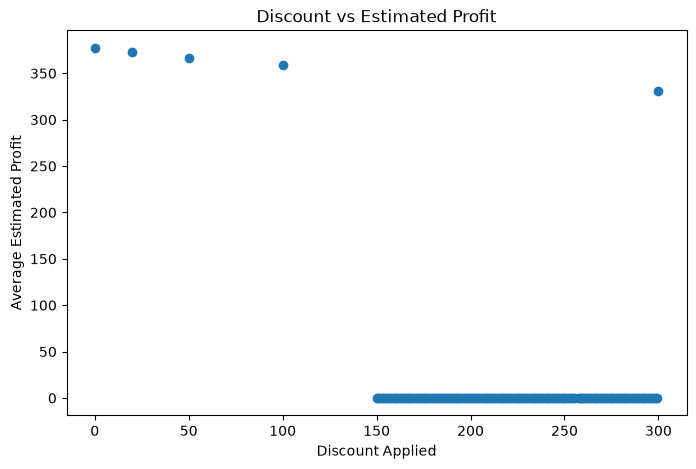

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    discount_profit["Discount_Applied"],
    discount_profit["Average_Profit"]
)

plt.xlabel("Discount Applied")
plt.ylabel("Average Estimated Profit")
plt.title("Discount vs Estimated Profit")

plt.show()

In [24]:
df_clean[
    "Discount_Applied"
].corr(
    df_clean["Estimated_Profit"]
)

np.float64(-0.043369693893332305)

In [25]:
df_clean.to_csv(
    "online_food_delivery_bivariate.csv",
    index=False
)